autorzy:Brojek

#  NLP Programming assignment LSA  / SVD



---

1. Create corpora containing at least 7 documents from three domains (sport, politics, etc.)
2. Construct document-term-matrix. Apply necessary preprocessing (remove stopwords)
3. Perform LSI using SVD
*   find matrices U, S, V.
*   visualize concepts as wordcloud of terms
*   visualize document topics on radar plot


---

# 1. Corpora





You can any corpus of your choice. Possible sources:


*   newspaper articles (web-scraping libraries might be useful),
*   any extracted texts - available under public url (git, pastebin)
*   nltk corpus (brown)

##  newspaper articles






In [1]:
import sys

from sklearn.pipeline import make_pipeline

In [2]:
#!git clone  https://github.com/mmazurek-wat/nlp-resources-edu.git
resource_path = '/content/nlp-resources-edu/05_Embedding_lab/'

sys.path.append(resource_path)

In [49]:
def clean(text):
    import re,html
    AGENCIES = r'\b(reuters|ap|afp|upi)\b'

    text = html.unescape(text)                              # pełne encje: &#39; -> '
    text = re.sub(r'#\d+;', "'", text)                      # uszkodzone encje: #39; -> '
    text = re.sub(r'\b(quot|amp|lt|gt);', ' ', text)        # uszkodzone nazwane encje bez &
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = text.replace('\\', ' ')
    text = re.sub(AGENCIES, ' ', text, flags=re.I)
    return re.sub(r'\s+', ' ', text).strip()

In [3]:
from datasets import load_dataset   # pip install datasets
ag = load_dataset("fancyzhx/ag_news")


In [4]:
#World (0), Sports (1), Business (2) i Sci/Tech (3)
categories= {
    0: 'World',
    1: 'Sports',
    2: 'Business',
    3: 'Sci/Tech'
}

Example

In [5]:
print(len(ag['test']))
print(categories[ag['test'][0]['label']])
print(ag['test'][0]['text'])

7600
Business
Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.


# Document term matrix

Prepare document term matrix (apply lemmatization)

In [6]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ------------- -------------------------- 4.2/12.8 MB 29.7 MB/s eta 0:00:01
     ----------------------------------- --- 11.5/12.8 MB 33.6 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 29.9 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [51]:
corpus = [clean(doc['text']) for doc in ag['test'] if doc]

In [52]:
import spacy
nlp = spacy.load("en_core_web_sm")
with nlp.select_pipes(disable=["parser", "ner"]):
    corpus_lemmatized = [" ".join([token.lemma_ for token in nlp(doc)]) for doc in nlp.pipe(corpus)]
print(corpus_lemmatized[1])

the race be on : Second private Team Sets Launch Date for Human Spaceflight ( SPACE.com ) SPACE.com - TORONTO , Canada -- a second team of rocketeer compete for the ' 10 million Ansari X Prize , a contest for privately fund suborbital space flight , have officially announce the first launch date for its manned rocket .


In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer,ENGLISH_STOP_WORDS

extra = {'quot', 'amp', 'lt', 'gt', 'href', 'http', 'www', 'com', 'said', 'say', 'new'}
vectorizer = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS|extra), norm="l2")
dtm = vectorizer.fit_transform(corpus_lemmatized)
terms = vectorizer.get_feature_names_out()

In [55]:
print(terms)


['00' '000' '000bn' ... 'zurich' 'zvonareva' 'zwelinzima']


Find indexes of sample tokens:

In [56]:
sample_terms = ['baseball', 'launch', 'police', 'amsterdam']

# indexes=[(i,term) for i,term in enumerate(terms) if term in sample_terms]

indexes=[vectorizer.vocabulary_[term] for term in sample_terms if term in vectorizer.vocabulary_]

print(sample_terms)
print(indexes)

['baseball', 'launch', 'police', 'amsterdam']
[1912, 9303, 12447, 1146]


Part of dtm matrix for selected terms:

In [57]:
print(sample_terms)
print(dtm[:,[i for i in indexes]].todense())

['baseball', 'launch', 'police', 'amsterdam']
[[0.         0.         0.         0.        ]
 [0.         0.23449928 0.         0.        ]
 [0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.        ]
 [0.         0.         0.         0.        ]
 [0.         0.         0.         0.        ]]


#  SVD

## Rozkład SVD (LSA) – opis wyników

Macierz dokument–termin $X$ (TF-IDF) rozkładamy w przybliżeniu jako:

$$X \approx U \, \Sigma \, V^T$$

| Obiekt w kodzie | Symbol | Kształt | Znaczenie |
|---|---|---|---|
| `New coordinates` | $U\Sigma$ (po normalizacji L2: wiersze o długości 1) | (7600, 4) | Współrzędne dokumentów w 4-wymiarowej przestrzeni ukrytej. Wiersz = dokument, kolumna = wymiar. |
| `Matrix V` | $V^T$ | (4, 18447) | Wagi terminów w każdym wymiarze. Wiersz = wymiar, kolumna = słowo ze słownika. Duża wartość bezwzględna oznacza silny wpływ słowa na wymiar. |
| `Singular values` | $\Sigma$ | (4,) | Ważność wymiarów, posortowana malejąco. Pierwszy wymiar niesie najwięcej informacji. |

### Interpretacja
- Pierwszy wymiar zwykle ma wszystkie wartości dodatnie i odpowiada ogólnej "obecności słownictwa".
- Kolejne wymiary opisują kontrasty tematyczne: wartości dodatnie i ujemne oznaczają przeciwne strony osi.
- Znak wymiaru jest arbitralny (odwrócenie znaku w $U$ i $V^T$ nie zmienia iloczynu).
- Normalizacja L2 skaluje wiersze do długości 1 i nie zmienia znaków. Jest przydatna do podobieństwa kosinusowego.


| Symbol       | Co to jest                       | Kształt u ciebie | Jak to dostać                 |
| ------------ | -------------------------------- | ---------------- | ----------------------------- |
| UΣU  | współrzędne dokumentów           | (7600, 4)        | svd.fit_transform(X)          |
| Σ  | wartości osobliwe                | (4,)             | svd.singular_values_          |
| V^T     | wagi terminów                    | (4, 18447)       | svd.components_               |
| U         | współrzędne dokumentów bez skali | (7600, 4)        | coords / svd.singular_values_ |

## SVD - matrices

In [83]:
from sklearn.decomposition import TruncatedSVD
from scipy.sparse import csr_matrix
import numpy as np
svd=TruncatedSVD(n_components=5, random_state=42)
emb=svd.fit_transform(dtm)
V=svd.components_
sing=svd.singular_values_


print("New coordinates, shape: ", emb.shape)
print(emb)
print("Matrix V, shape: ", V.shape)
print(V)
print("Singular values:")
print(sing)

New coordinates, shape:  (7600, 5)
[[ 0.04598327 -0.02027534 -0.00901534 -0.01357291  0.05870923]
 [ 0.09641751 -0.0543992   0.032298    0.05942389 -0.00555861]
 [ 0.06681747 -0.02020574  0.03766782  0.03885509 -0.00316548]
 ...
 [ 0.06606355 -0.04059524  0.01620169  0.08591547 -0.03873866]
 [ 0.04336023 -0.00529835 -0.00920381  0.00427823  0.02296204]
 [ 0.05550542 -0.01001263  0.04742481 -0.01640785 -0.003428  ]]
Matrix V, shape:  (5, 18240)
[[ 7.66032222e-04  3.97493865e-02  5.98136511e-04 ...  1.44755175e-03
   5.36573170e-04  2.13256317e-04]
 [-8.83129434e-04 -7.75864214e-03  1.46050728e-05 ... -5.19717020e-04
  -5.60903428e-04 -2.76491706e-04]
 [-1.50216258e-04  3.11625080e-03  8.48120143e-04 ...  3.83081434e-04
  -1.55517415e-04 -2.23257069e-04]
 [ 3.14529902e-03  6.79776285e-03 -1.20060930e-04 ...  5.88106736e-04
   1.97855809e-03  1.86095572e-05]
 [-6.77562353e-04 -1.12695839e-03 -1.68107615e-04 ...  2.09321804e-04
  -1.00175224e-03  4.57756020e-04]]
Singular values:
[7.447198

## SVD normalized

In [58]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
lsa=make_pipeline(TruncatedSVD(n_components=4, random_state=42),Normalizer(copy=False))
emb=lsa.fit_transform(dtm)
svd=lsa[0]
V=svd.components_
sing=svd.singular_values_


print("New coordinates, shape: ", emb.shape)
print(emb)
print("Matrix V, shape: ", V.shape)
print(V)
print("Singular values:")
print(sing)

New coordinates, shape:  (7600, 4)
[[ 0.85989229 -0.39793837 -0.21339692 -0.23810092]
 [ 0.75125612 -0.41099229  0.27037648  0.43999561]
 [ 0.7606851  -0.22724097  0.42682279  0.43306124]
 ...
 [ 0.55577439 -0.33325006  0.14650959  0.74739158]
 [ 0.95900799 -0.109964   -0.24680339  0.08543813]
 [ 0.72408507 -0.13686566  0.6283574  -0.2492701 ]]
Matrix V, shape:  (4, 18240)
[[ 7.66956377e-04  3.97188151e-02  5.97439839e-04 ...  1.44907459e-03
   5.36721760e-04  2.13212719e-04]
 [-9.31607719e-04 -1.02612498e-02 -3.40501949e-05 ... -4.73837811e-04
  -6.26445126e-04 -2.71037155e-04]
 [-1.56802733e-04  2.91005655e-03  8.85580315e-04 ...  3.76950633e-04
  -1.77937268e-04 -2.26031856e-04]
 [ 3.05189762e-03  6.67100297e-03 -4.25423517e-05 ...  6.74732360e-04
   2.15162623e-03  2.20764622e-05]]
Singular values:
[7.44719757 5.44153235 5.14610269 4.76898165]


In [84]:
print('Term to topic coordinates for selected  sample terms:')
print(sample_terms)
print(V[:,[i for i in indexes]])

Term to topic coordinates for selected  sample terms:
['baseball', 'launch', 'police', 'amsterdam']
[[ 0.01498742  0.04579056  0.02923193  0.00367082]
 [-0.01316914 -0.02925035 -0.05554193 -0.00123346]
 [ 0.00059563  0.05564452 -0.05242361  0.00170778]
 [ 0.03691098 -0.02666401 -0.04518966  0.00240196]
 [-0.00531469 -0.0096279  -0.0681034  -0.00294582]]


## Topic visualization with wordclouds

For each topic generate pair of wordcloud charts: one with postive coordinates, one with negative (only)

In [86]:
def generate_wordcloud(weights, terms, top_n=50,bg='white', cmap='viridis'):

    top = np.argsort(weights)[::-1][:top_n]
    freq = {terms[j]: float(weights[j]) for j in top if weights[j] > 0}
    if not freq:
        return None
    wc = WordCloud(width=600, height=400, background_color=bg,
                   colormap=cmap, random_state=42)
    return wc.generate_from_frequencies(freq)

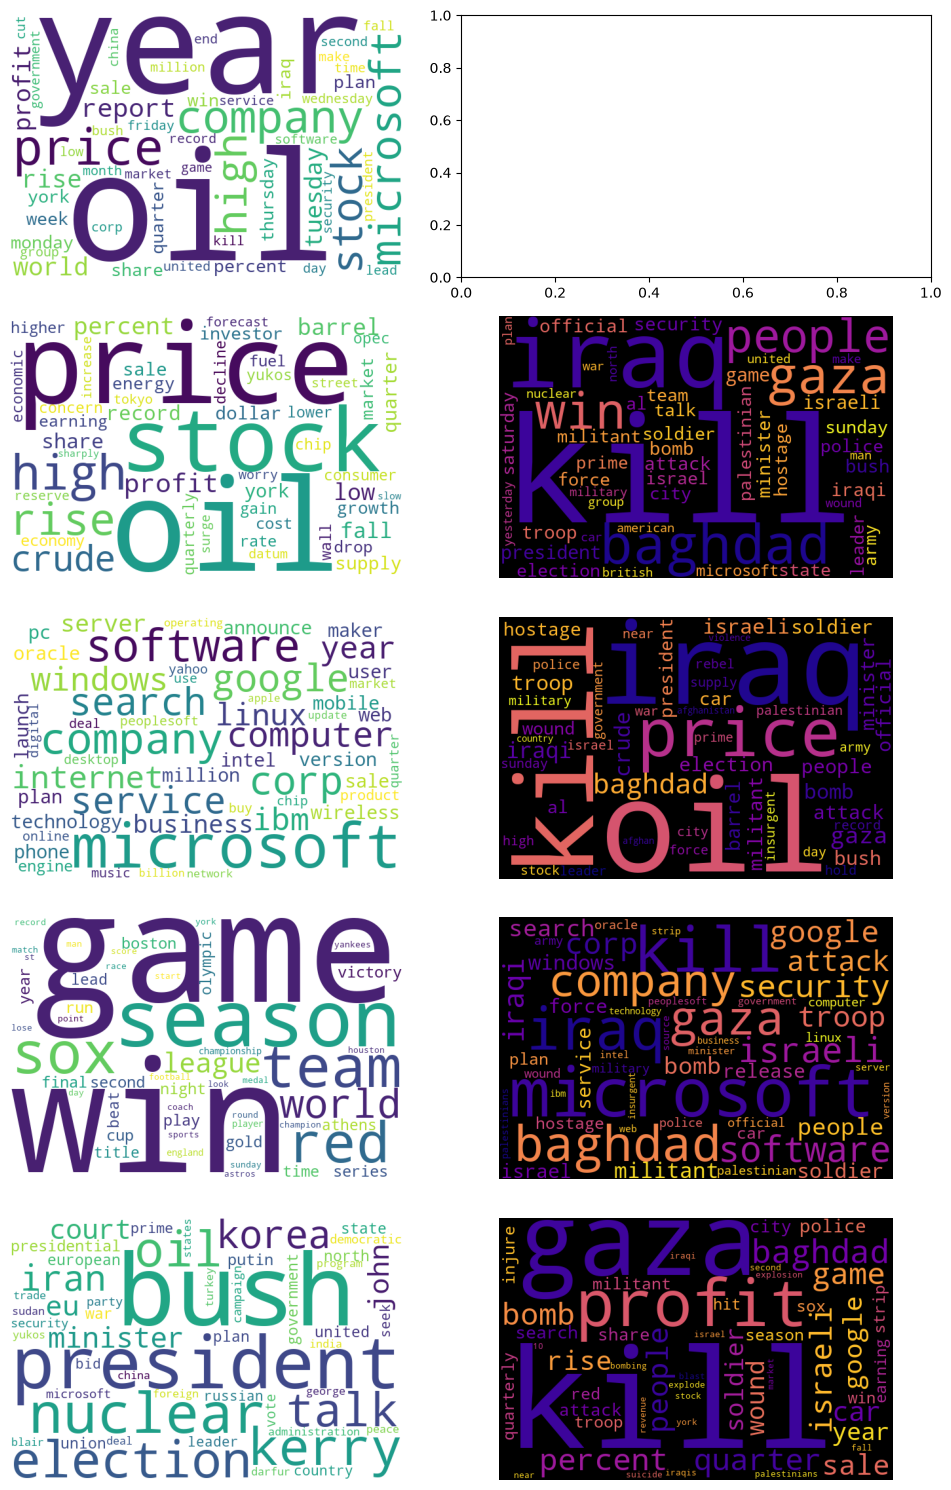

In [92]:
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from wordcloud import WordCloud
from sklearn.preprocessing import MinMaxScaler


fig = plt.figure(figsize=(10,15))
n_topics = 5


for i in range(n_topics):
    ax = fig.add_subplot(n_topics,2,2*i+1)
    #posititive
    wordcloud = generate_wordcloud(V[i], terms, bg='white', cmap='viridis')
    if wordcloud:
      ax.imshow(wordcloud)
      ax.axis('off')


    #negative
    ax = fig.add_subplot(n_topics,2,2*i+2)
    wordcloud = generate_wordcloud(-V[i],terms, bg='black', cmap='plasma')

    if wordcloud:
      ax.imshow(wordcloud)
      ax.axis('off')

plt.tight_layout()
plt.show()


If we compare created categories to the provided one, we could see that:
- the first one can represent business
- second tech
- third sports
- fourth world

In [64]:
import numpy as np
lo, hi = emb.min(), emb.max()
print("Range of coordinates: ", lo, hi)

Range of coordinates:  -0.2667440262480575 0.4551930093411108


## Document visualization with radar charts

For randomly selected 5 files from each category plot radarchart.


In [105]:
import plotly.graph_objects as go
def radarChart(U, doc_id):
    U=U[:, 1:]
    dims = [f"dim{k+1}" for k in range(U.shape[1])]
    r = U[doc_id].tolist()
    m = max(abs(v) for v in r)

    fig = go.Figure(
      go.Scatterpolar(
        r=r + [r[0]],
        theta=dims + [dims[0]],
        fill='toself',

      )
    )



    fig.update_layout(
      polar=dict(
        radialaxis=dict(
          visible=True,
          range=[-m,m]#[U.min(), U.max()]
        )),
      showlegend=False
    )

    fig.show()

In [110]:
import random
idx = random.randrange(len(corpus))


print(corpus[idx])
print(categories[ag['test'][idx]['label']])
radarChart(emb,idx)


TUC urges 6 minimum wage rate The UK's minimum wage should rise to rise to 6 an hour in the next two years, the TUC says, but business calls the proposal "totally irresponsible".
Business


In case of plotly not showing



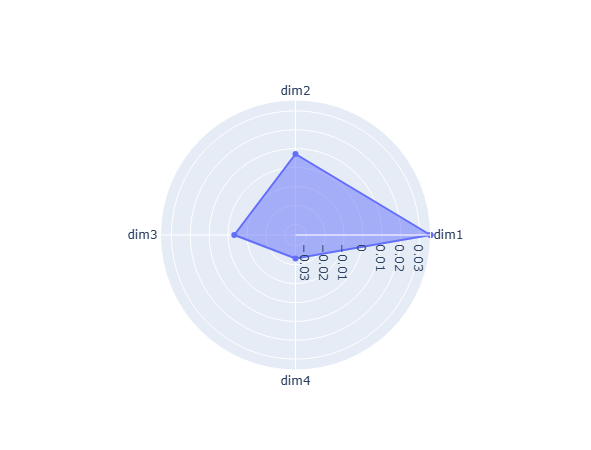